In [ ]:
# Audio I/O: What the realtime API actually receives

# A "live" voice model never sees as WAV file. It sees a stream of small base64 chunks of raw PCM16 audio. This notebook follows one recording from the microphone all the way to the exact JSON event that the REAltime API would receive.

# mic > int16 samples -> PCM16 bytes -> chunks -> base64 -> {"type": "input_audio_buffer.append"}

# No API calls here. Helpers live in live/audio.py

In [ ]:
import json
import numpy as np
import sounddevice as sd
import matplotlib.pyplot as plt
from IPython.display import Audio
from live import audio

In [ ]:
# Which devices will be used?

# sd.default.device = (input index, output index). Use headphones in later notebooks, so the model does not hear itself

devices = sd.query_devices()
default_in, default_out = sd.default.device
devices[default_in]['name'], devices[default_out]['name']

('Headset (EarPods)', 'Headset (EarPods)')

In [ ]:
# The audio format the API expects

# OpenAI Realtime uses 24 KHz, mono, 16-bit signed integers (PCM16), for both input and output.

audio.RATE, audio.CHANNELS, audio.DTYPE

(24000, 1, 'int16')

In [ ]:
# Record 3 seconds (say something!)

# The result is just a numpy array of integers. Each one is the mic membrane position at one instance, from -32768 to 32767.

rec = audio.record(3)
rec.shape, rec.dtype, rec.min(), rec.max()

((72000,), dtype('int16'), np.int16(-3942), np.int16(3567))

In [ ]:
# Number of samples = seconds x rate
len(rec), 3 * audio.RATE

(72000, 72000)

In [ ]:
# LOUDNESS (RMS): silence is about 0.00x, speech about 0.02-0.2.
# Server-side VAD uses a signal like this to decide that you are talking. 

audio.rms(rec)

0.0208781398832798

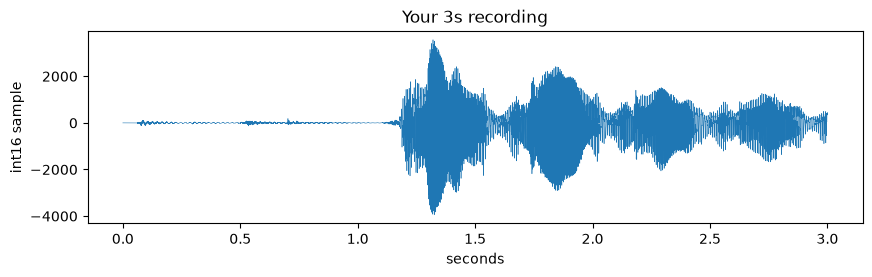

In [ ]:
t = np.arange(len(rec)) / audio.RATE
plt.figure(figsize=(10, 2.5))
plt.plot(t, rec, lw=0.4)
plt.xlabel("seconds")
plt.ylabel("int16 sample")
plt.title("Your 3s recording")
plt.show()

In [ ]:
Audio(rec, rate=audio.RATE) # in-notebook player

In [ ]:
# int16 -> float

# DSP code (and our RMS) works on floats in [-1, 1]. The wire format is int16. Converting back and forth loses at most 1 unit, because of rounding.

f = audio.pcm16_to_float(rec)
f.dtype, round(float(f.min()), 4), round(float(f.max()), 4)

(dtype('float32'), -0.1203, 0.1089)

In [ ]:
back = audio.float_to_pcm16(f)
int(np.abs(back.astype(int) - rec).max()) # max round-trip error, in int16 units

1

In [ ]:
# Samples => PCM16 bytes

# Each sample takes 2 bytes, little-endian. This is all "PCM16" means: no header, no compression.

pcm = audio.to_bytes(rec)
len(pcm), len(rec) * 2, pcm[:8]

(144000, 144000, b'\x00\x00\x00\x00\xff\xff\x00\x00')

In [ ]:
# Bytes -> Chunks

# We stream audio as it is captured instead of sending it all at once. Each chunk is a short slice of time. 100ms is a good balance: smaller chunks means lower latency but more messages.

CHUNK_MS = 100
chunk_bytes = audio.RATE * CHUNK_MS // 1000 * 2 # samples per chunk x 2 bytes
chunks = [pcm[i:i + chunk_bytes] for i in range(0, len(pcm), chunk_bytes)]

In [ ]:
chunk_bytes, len(chunks)

(4800, 30)

In [ ]:
# Chunk -> base64

# JSON cannot carry raw bytes, so each chunk is base64-encoded. That makes it about 33% bigger.

b64 = audio.to_b64(chunks[0])
len(chunks[0]), len(b64), b64[:60]

(4800, 6400, 'AAAAAP//AAAAAAAAAAD//wAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAD/')

In [ ]:
# The exact event sent over the WebSocket

# Notebook 03 sends one of these every 100ms while you talk:

event = {
    "type": "input_audio_buffer.append",
    "audio": b64
}
print(json.dumps(event)[:120] + " ...")
len(json.dumps(event))

{"type": "input_audio_buffer.append", "audio": "AAAAAP//AAAAAAAAAAD//wAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAD//wAAAAAAAAAA ...


6450

In [ ]:
# The reverse path (what we will do with the model's audio)

# The server sends 'response.output_audio.delta' events with the same base64 PCM16. Decoding gives back the identical samples.

decoded = audio.from_bytes(audio.from_b64(b64))
assert np.array_equal(decoded, rec[:len(decoded)])

decoded.shape, decoded.dtype

((2400,), dtype('int16'))

In [ ]:
audio.play(rec) # through the speakers via sounddevice: this is how model audio will be played

In [ ]:
# Takeaways

# - The API's audio is just int16 numbers at 24 KHz. There is nothing more to it.
# - "Streaming" = cut the byte stream into ~100 ms chunks and send each one as a base64 JSON event.
# - The output path is the mirror image: base64 -> bytes -> int16 -> speaker

# Next (02): open the websocket, configure the session, send text, and hear the model's audio reply.